In [1]:
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

In [2]:
sample = "BII_S9" # "BII_S9_15mM_LV4_PBS_FVII"
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

Fit results with 1σ uncertainties:

sigma_head_fit = 0.33527 ± 0.018606
sigma_tail_fit = 0.6 ± 0.03482
rho_head_fit = 1 ± 0.037364
eps_head_fit = 1.8828 ± 0.017743
scale_fit = 0.48 ± 0.029559
chi2 = 17742


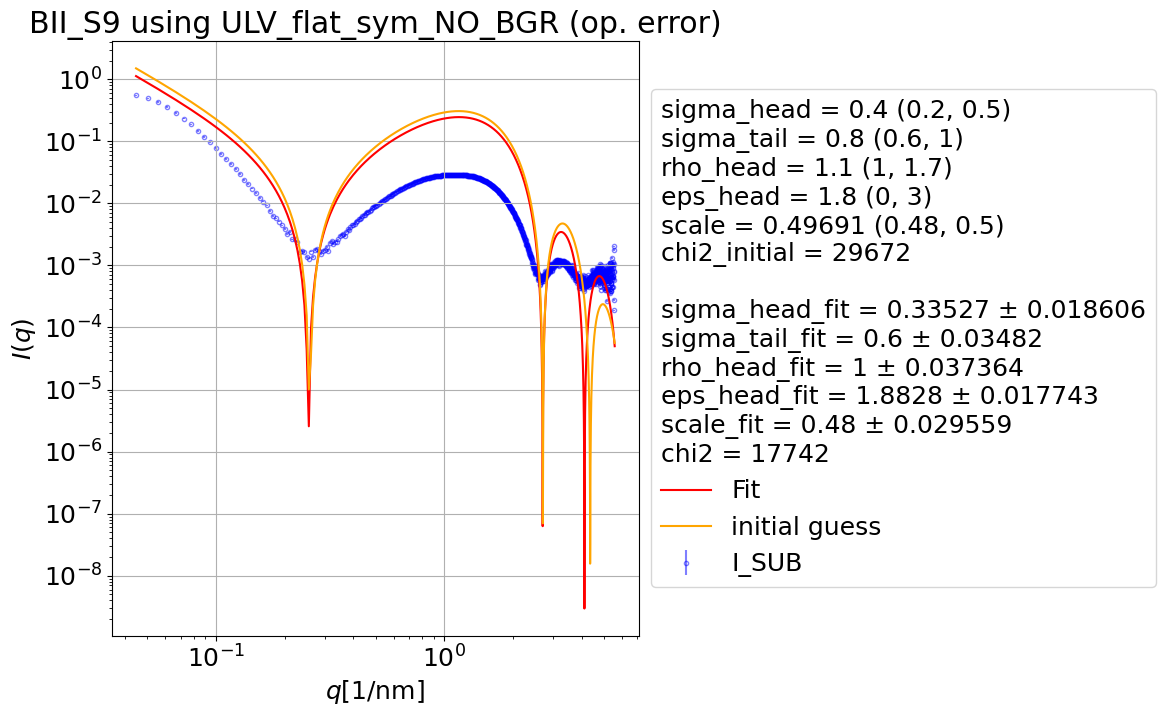

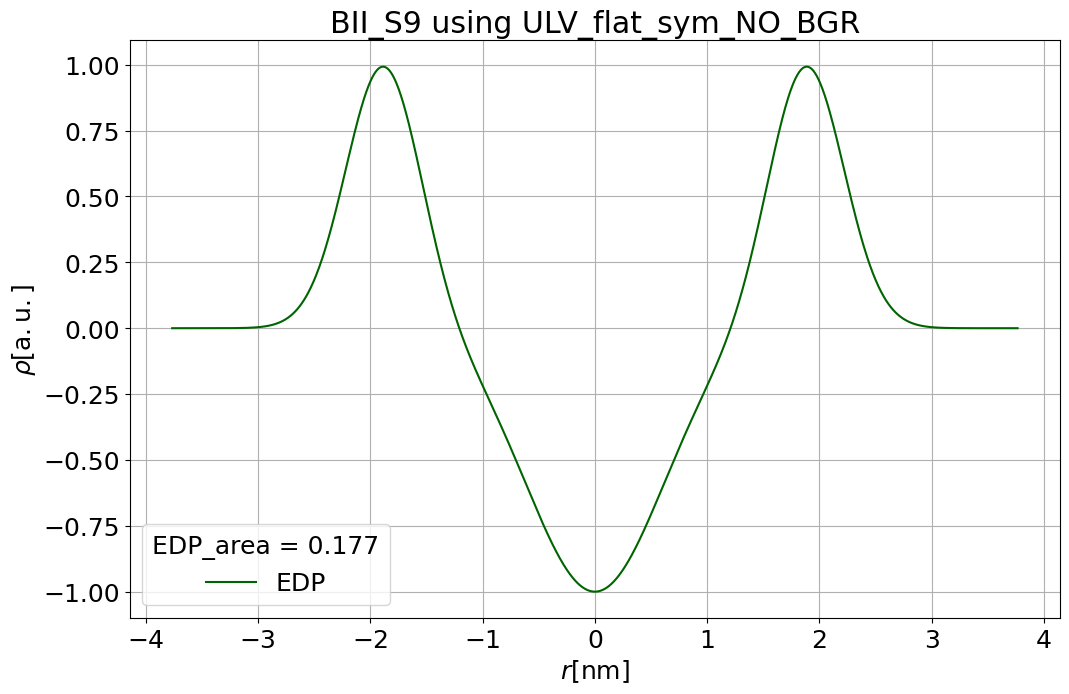

In [3]:
fit_function = fit.ULV_flat_sym_NO_BGR
plt.close("all")

param_set = "flat_sym_NO_BGR"

q     = q
I     = I
I_err = np.abs(I / 30) #Ierr

# ========================== Parameters ==========================
R       = 0
sigma_R = 0

sigma_head   = 0.4
sigma_tail = 0.8
rho_head   = 1.1
eps_head = 1.8

scale = 0.49691 

# ========================== Setting Bounds ==============================

p0           = [sigma_head, sigma_tail, rho_head,   eps_head,    scale]     
lower_bounds = [       0.2,        0.6,        1,          0,     0.48]
upper_bounds = [       0.5,          1,      1.7,          3,      0.5]


#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = fit.param_names.get(param_set)

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text = fit.info(q, I, I_err, param_names, p0, popt, perr, fit_function)

residuals = I - fit_function(q, *p0)
initial_chi2 = np.sum((residuals / I_err)**2) / (len(I) - len(p0) - 1)
names2 = [name[:-4] for name in param_names]
info_text2 = "\n".join(f"{name} = {val:.5g} ({lower_bounds[i]}, {upper_bounds[i]})" for name, val, i in zip(names2, p0, range(len(p0))))
info_text2 += f"\nchi2_initial = {initial_chi2:.5g}\n \n"
info_text_print = info_text2 + info_text
# with open(target_folder/"info_texts_LV4.txt", "a", encoding="utf-8") as k:
#     k.write(f"\n\n{sample} f={fac} using {fit_function.__name__}_q0p8\n" + info_text_print + "\n###########################################\n")
#=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 1000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='pow law bgr')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{sample} using {fit_function.__name__} (op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_op_error.png", bbox_inches='tight', pad_inches=0.05)
plt.show()

fig=fit.EDP_plot(0, sigma_head_fit, sigma_head_fit, sigma_tail_fit, rho_head_fit, rho_head_fit, eps_head_fit, eps_head_fit, info_text, 
             f'{sample} using {fit_function.__name__}')
# # fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error.png", dpi=400, bbox_inches='tight', pad_inches=0.05)
# pow_law_reality_check(c2_fit, c3_fit, c4_fit)
# type(popt)


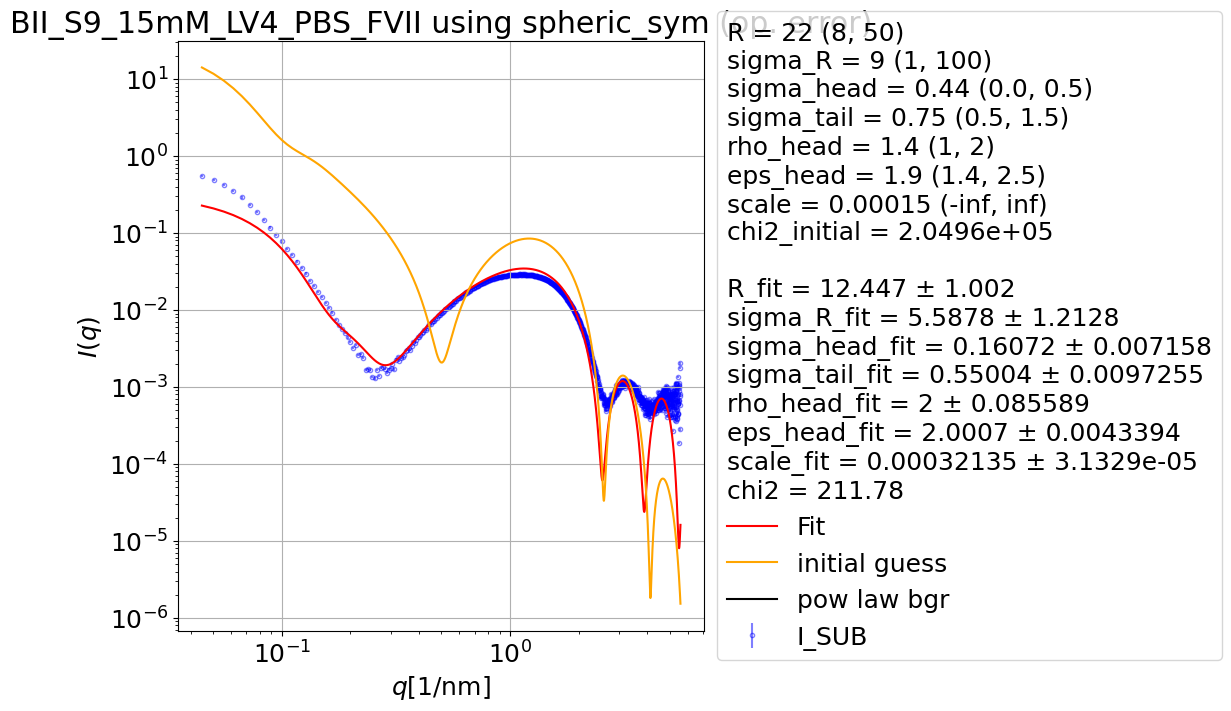

In [12]:
# SPHERIC SYM NO BGR
fit_function = lambda q, R,    sigma_R, sigma_head, sigma_tail, rho_head,  eps_head,    scale: fit.ULV_spheric_sym(q, R,    sigma_R, sigma_head, sigma_tail, rho_head,  eps_head,    scale,      0, 0, 0)
#fit_function = fit.ULV_spheric_sym_num
plt.close("all")

param_set = "spheric_sym"

q     = q
I     = I
I_err = np.abs(I * 1/30) # Ierr

# ========================== Parameters ==========================
R       = 22
sigma_R = 9

sigma_head =0.44# 0.3929 
sigma_tail = 0.75
rho_head = 1.4 #1.2256 
eps_head = 1.9
scale = 0.00015
c2 = 0 
c3 = 0
c4 = 0

# ========================== Setting Bounds ==============================
p0           = [   R,    sigma_R, sigma_head, sigma_tail, rho_head,  eps_head,    scale] #,      c2,      c3,      c4]
lower_bounds = [   8,          1,        0.0,        0.5,        1,       1.4,  -np.inf] #,       0,       0,       0]
upper_bounds = [  50,        100,        0.5,        1.5,        2,       2.5,  +np.inf] #,   1e-10,   1e-10,   1e-10]

#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = ["R_fit", "sigma_R_fit", "sigma_head_fit", "sigma_tail_fit", 
               "rho_head_fit", "eps_head_fit", "scale_fit"]

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)

#=========================== Plot ===========================================
q_fit = np.linspace(min(q), max(q), 1000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, R, sigma_R, sigma_head, sigma_tail, rho_head,   eps_head,   scale), color='orange', label='initial guess')
plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, 0), color='black', label='pow law bgr')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using spheric_sym (op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_operative_error.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()
# fig = fit.EDP_plot(R_fit, sigma_head, sigma_head, sigma_tail, rho_head, rho_head, eps_head, eps_head, info_text_print, 
#              f'{sample} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# pow_law_reality_check(c2_fit, c3_fit, c4_fit)


In [20]:
# SPHERIC SYM + c4
fit_function = lambda q, R,    sigma_R, sigma_head, sigma_tail, rho_head,  eps_head,    scale, c4: fit.ULV_spheric_sym(q, R,    sigma_R, sigma_head, sigma_tail, rho_head,  eps_head,    scale,      0, 0, c4)
#fit_function = fit.ULV_spheric_sym_num
plt.close("all")

param_set = "spheric_sym"

q     = q
I     = I
I_err = np.abs(I * 1/30) # Ierr

# ========================== Parameters ==========================
R       = 25
sigma_R = 10

sigma_head =0.34# 0.3929 
sigma_tail = 0.9
rho_head = 1.5 #1.2256 
eps_head = 1.7
scale = 0.00015
c2 = 0 
c3 = 0
c4 = 0.00027

# ========================== Setting Bounds ==============================
p0           = [   R,    sigma_R, sigma_head, sigma_tail, rho_head,  eps_head,    scale,      c4] #,      c2,      c3,      c4]
lower_bounds = [   8,          1,        0.0,        0.5,        1,       1.4,  -np.inf, -np.inf] #,       0,       0,       0]
upper_bounds = [  50,        100,        0.5,        1.5,        2,       2.5,  +np.inf, +np.inf] #,   1e-10,   1e-10,   1e-10]


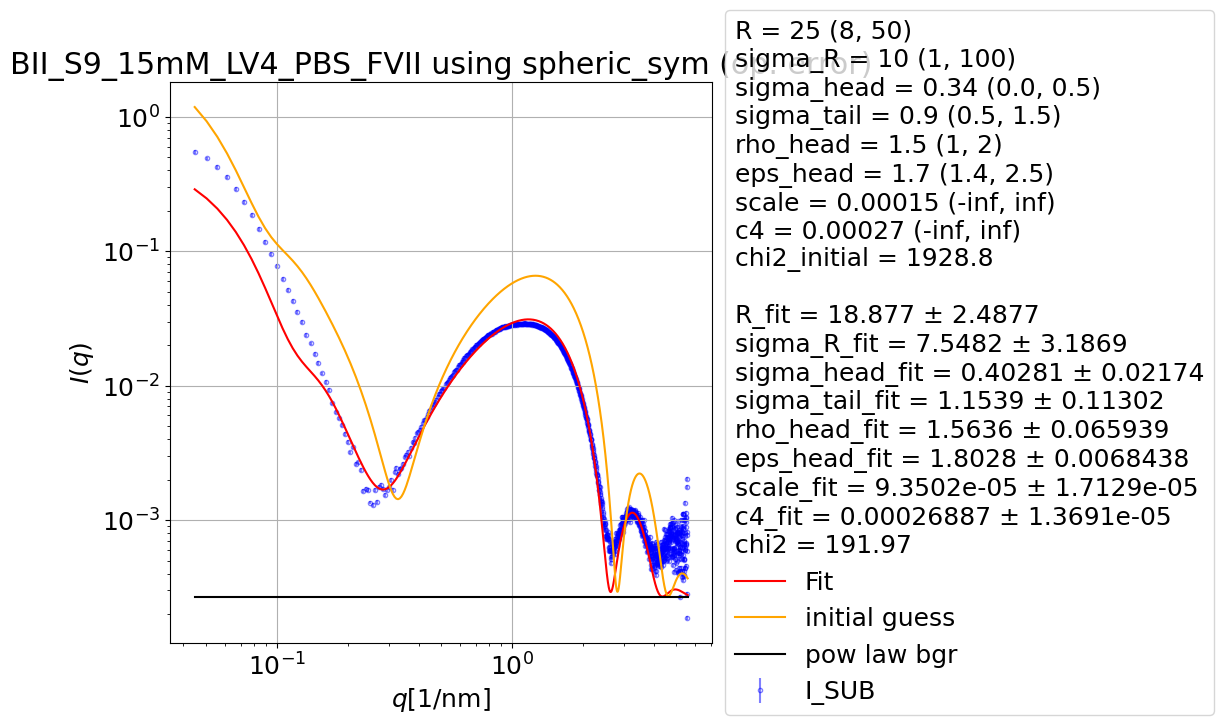

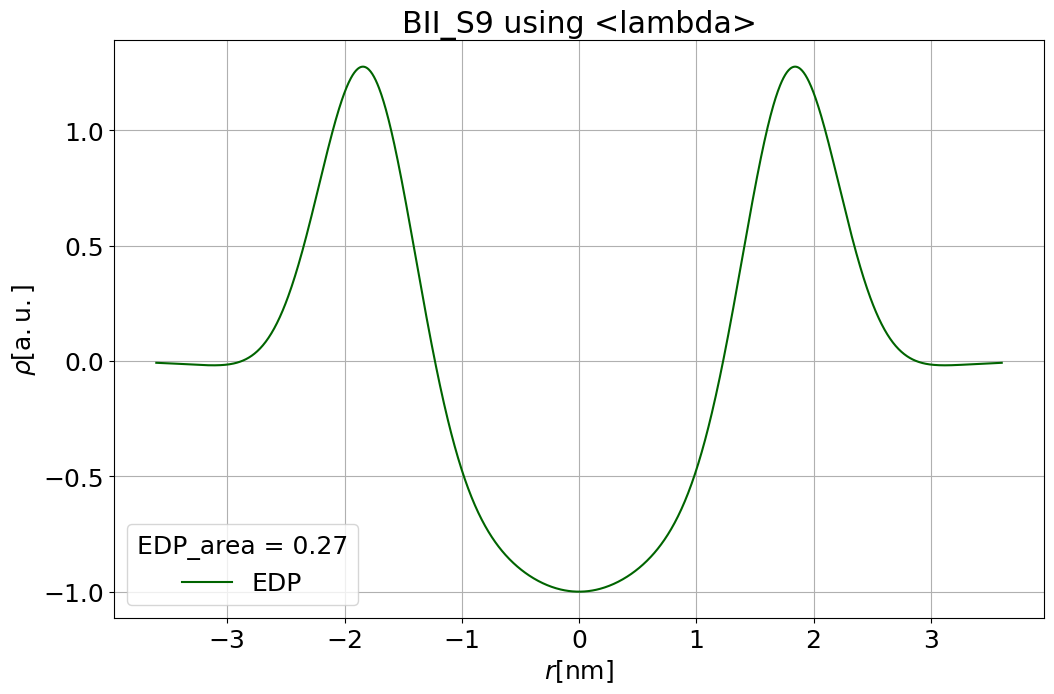

In [21]:
#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = ["R_fit", "sigma_R_fit", "sigma_head_fit", "sigma_tail_fit", 
               "rho_head_fit", "eps_head_fit", "scale_fit", "c4_fit"]

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)

#=========================== Plot ===========================================
q_fit = np.linspace(min(q), max(q), 1000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, R, sigma_R, sigma_head, sigma_tail, rho_head,   eps_head,   scale, c4), color='orange', label='initial guess')
plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, c4_fit), color='black', label='pow law bgr')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using spheric_sym (op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_operative_error.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()
fig = fit.EDP_plot(R_fit, sigma_head_fit, sigma_head_fit, sigma_tail_fit, rho_head_fit, rho_head_fit, eps_head_fit, eps_head_fit, info_text_print, 
             f'{sample} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# pow_law_reality_check(c2_fit, c3_fit, c4_fit)


In [30]:
# FLAT ASYM NO BGR
fit_function = lambda q, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale: fit.ULV_flat_asym(q, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale,      0, 0, 0)
plt.close("all")

param_set = "flat_asym"

q     = q
I     = I
I_err = np.abs(I / 30) #Ierr

# ========================== Parameters ==========================
R       = 0
sigma_R = 0

sigma_h1 = 0.4
sigma_h2 = 0.2
sigma_tail = 0.75 
rho_h1 = 1
rho_h2 = 2
eps_head = 1.8305 
scale = 0.037848 

c2    = 0
c3    = 0
c4    = 0
# ========================== Setting Bounds ==============================

p0           = [sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale] #,      c2,      c3,      c4]
lower_bounds = [    0.10,     0.10,        0.5,    0.0,    0.0,        1.7,     -np.inf] #,       0,       0,       0]
upper_bounds = [     0.6,      0.6,        0.9,    4.0,    4.0,          2,     +np.inf] #,   1e-10,   1e-10,   1e-10]

Fit results with 1σ uncertainties:

sigma_h1_fit = 0.55903 ± 0.012327
sigma_h2_fit = 0.16493 ± 0.0085949
sigma_tail_fit = 0.89062 ± 0.030128
rho_h1_fit = 0.80288 ± 0.031084
rho_h2_fit = 3.3392 ± 0.11885
eps_head_fit = 1.8363 ± 0.0096918
scale_fit = 0.040775 ± 0.0013829
chi2 = 143.46


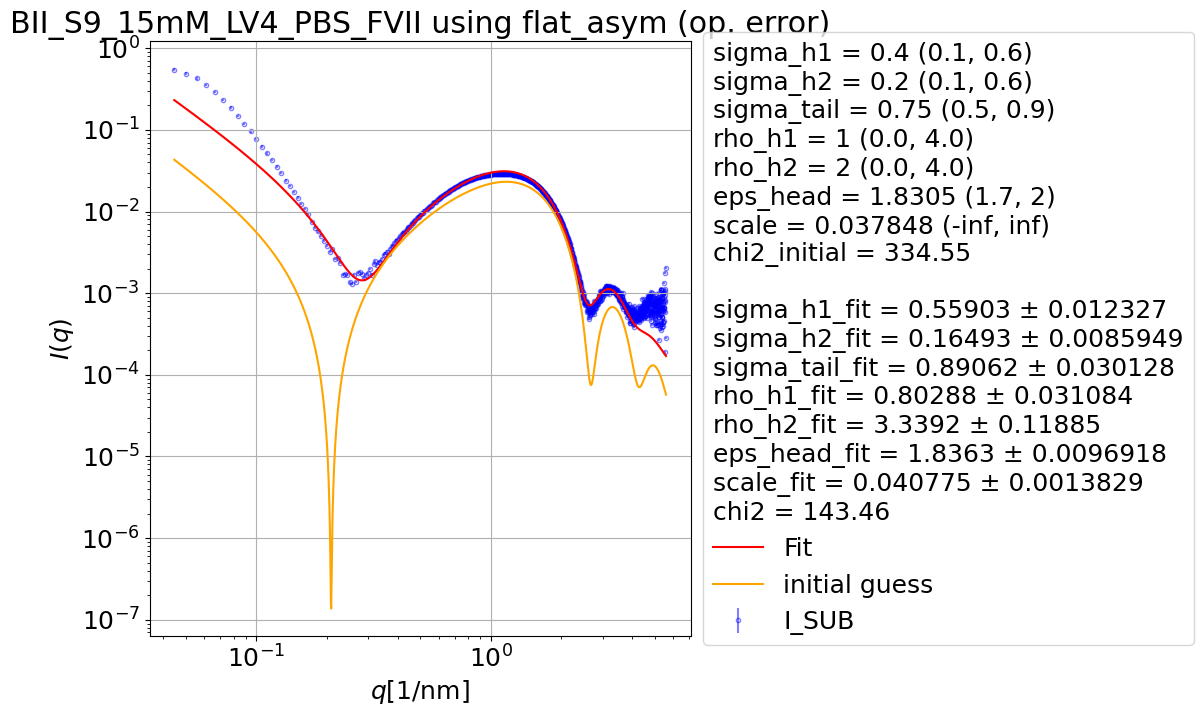

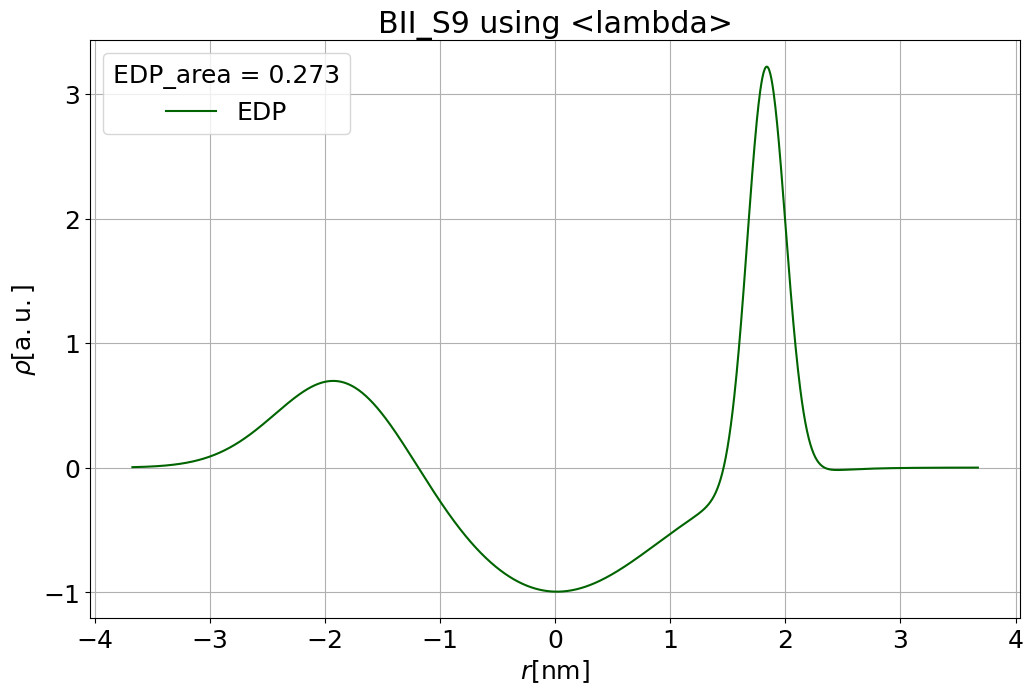

In [31]:
#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=20000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = fit.param_names.get(param_set)

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text = fit.info(q, I, I_err, param_names, p0, popt, perr, fit_function)

residuals = I - fit_function(q, *p0)
initial_chi2 = np.sum((residuals / I_err)**2) / (len(I) - len(p0) - 1)
names2 = [name[:-4] for name in param_names]
info_text2 = "\n".join(f"{name} = {val:.5g} ({lower_bounds[i]}, {upper_bounds[i]})" for name, val, i in zip(names2, p0, range(len(p0))))
info_text2 += f"\nchi2_initial = {initial_chi2:.5g}\n \n"

info_text_print = info_text2 + info_text
#=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 10000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='bgr')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using flat_asym (op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_operative_error_2.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()

# =========== EDP =====================================================================================
fig = fit.EDP_plot(0, sigma_h1_fit, sigma_h2_fit, sigma_tail_fit, rho_h1_fit, rho_h2_fit, eps_head_fit, eps_head_fit, info_text, 
             f'{sample} using {fit_function.__name__}')
# # fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error_2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)
# fig = fit.EDP_plot(0, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2, eps_head, eps_head, info_text, 
#                    f'{sample} using {fit_function.__name__} (initial guess)')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_INITIAL GUESS_op_error_2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# pow_law_reality_check(c2_fit, c3_fit, c4_fit)

In [ ]:
# FLAT ASYM + c4
fit_function = lambda q, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale, c4: fit.ULV_flat_asym(q, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale,      0, 0, c4)
plt.close("all")

param_set = "flat_asym"

q     = q
I     = I
I_err = np.abs(I / 30) #Ierr

# ========================== Parameters ==========================
R       = 0
sigma_R = 0

sigma_h1 = 0.4
sigma_h2 = 0.2
sigma_tail = 0.75 
rho_h1 = 1
rho_h2 = 2
eps_head = 1.8305 
scale = 0.037848 

c2    = 0
c3    = 0
c4    = 0.0001
# ========================== Setting Bounds ==============================

p0           = [sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2,   eps_head,       scale,      c4] #,      c2,      c3,      c4]
lower_bounds = [    0.10,     0.10,        0.5,    0.0,    0.0,        1.7,     -np.inf,  0.0001] #,       0,       0,       0]
upper_bounds = [     0.6,      0.6,        0.9,    4.0,    4.0,          2,     +np.inf, +np.inf] #,   1e-10,   1e-10,   1e-10]

Fit results with 1σ uncertainties:

sigma_h1_fit = 0.55508 ± 0.013561
sigma_h2_fit = 0.21074 ± 0.066026
sigma_tail_fit = 0.9 ± 0.10416
rho_h1_fit = 0.82012 ± 0.092915
rho_h2_fit = 2.6274 ± 0.58572
eps_head_fit = 1.8316 ± 0.025013
scale_fit = 0.041254 ± 0.0019943
c4_fit = 0.0001 ± 8.9936e-05
chi2 = 148.09


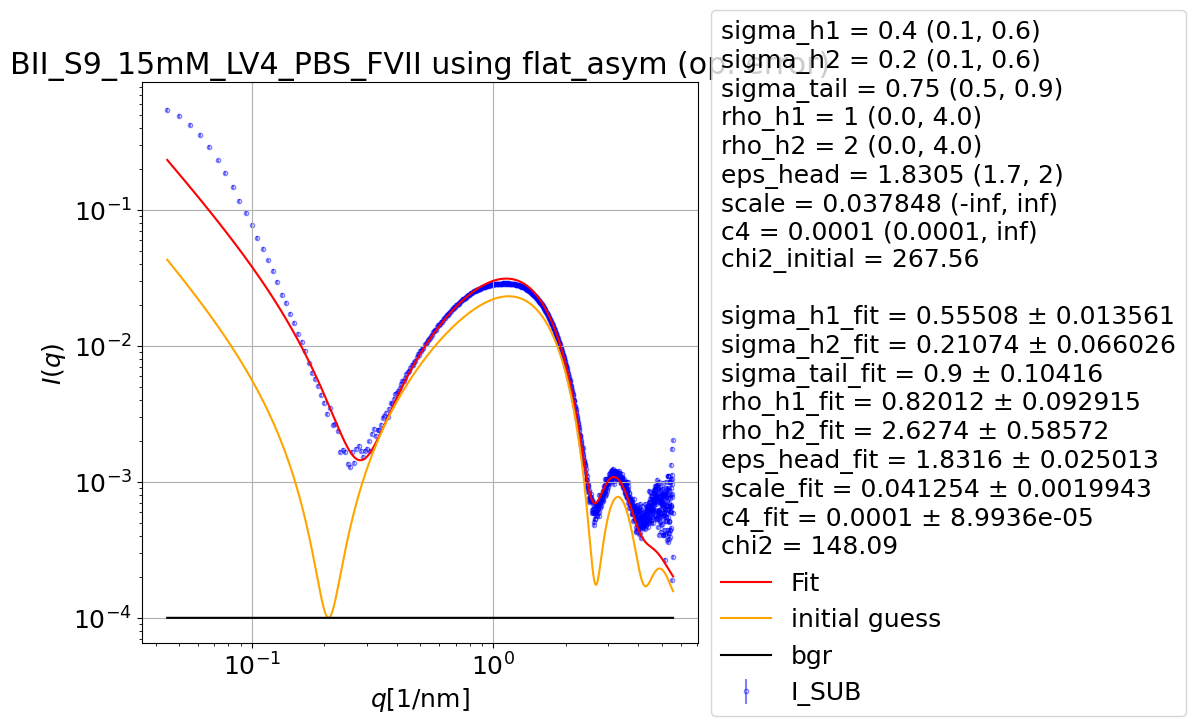

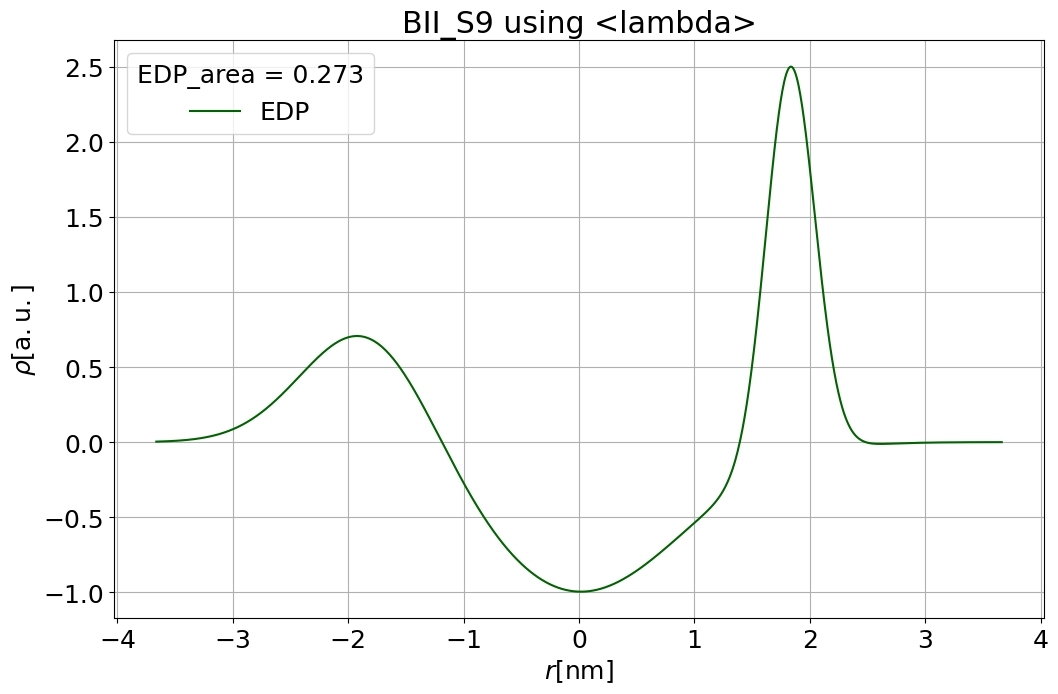

In [39]:
#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=20000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = ["sigma_h1_fit", "sigma_h2_fit", "sigma_tail_fit", "rho_h1_fit", "rho_h2_fit", 
                     "eps_head_fit", "scale_fit", "c4_fit"]

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text = fit.info(q, I, I_err, param_names, p0, popt, perr, fit_function)

residuals = I - fit_function(q, *p0)
initial_chi2 = np.sum((residuals / I_err)**2) / (len(I) - len(p0) - 1)
names2 = [name[:-4] for name in param_names]
info_text2 = "\n".join(f"{name} = {val:.5g} ({lower_bounds[i]}, {upper_bounds[i]})" for name, val, i in zip(names2, p0, range(len(p0))))
info_text2 += f"\nchi2_initial = {initial_chi2:.5g}\n \n"

info_text_print = info_text2 + info_text
#=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 10000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, c4_fit), color='black', label='bgr')
# plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using flat_asym (op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_operative_error_2.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()

# =========== EDP =====================================================================================
fig = fit.EDP_plot(0, sigma_h1_fit, sigma_h2_fit, sigma_tail_fit, rho_h1_fit, rho_h2_fit, eps_head_fit, eps_head_fit, info_text, 
             f'{sample} using {fit_function.__name__}')
# # fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error_2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)
# fig = fit.EDP_plot(0, sigma_h1, sigma_h2, sigma_tail, rho_h1, rho_h2, eps_head, eps_head, info_text, 
#                    f'{sample} using {fit_function.__name__} (initial guess)')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_INITIAL GUESS_op_error_2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# pow_law_reality_check(c2_fit, c3_fit, c4_fit)

In [48]:
# SPHERIC ASYM
fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale: fit.ULV_spheric_asym(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, 0)

param_set = "spheric_asym"
q     = q
I     = I
I_err = np.abs(I / 30) #Ierr

# q_mask = q >= 0.1
# I_err[q_mask] = np.abs(I[q_mask] / 15)

# ========================== Parameters ==========================
R = 18
sigma_R = 7
rho_h1 = 1.8
rho_h2 = 1.44
sigma_h1 = 0.3
sigma_h2 = 0.4
sigma_c = 0.75
z_h = 1.75
scale = 0.00013965

# ========================== Setting Bounds ==============================
p0           = [   R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale] #,      c2,      c3,      c4]
lower_bounds = [  17,          5,        0,        0,        0.2,       0.2,      0.5,    1.5, -np.inf] #,       0,       0, -np.inf]
upper_bounds = [  30,         12,        4,        4,        0.6,       0.6,      1.0,      2, +np.inf] #,       4,     0.5, +np.inf]

[17, 5, 3.357, 0.819, 0.2, 0.5624, 1, 1.814, 0.0001254]
R = 18 (17, 30)
sigma_R = 7 (5, 12)
rho_h1 = 1.8 (0, 4)
rho_h2 = 1.44 (0, 4)
sigma_h1 = 0.3 (0.2, 0.6)
sigma_h2 = 0.4 (0.2, 0.6)
sigma_c = 0.75 (0.5, 1.0)
z_h = 1.75 (1.5, 2)
scale = 0.00013965 (-inf, inf)
chi2_initial = 28063
 
R_fit = 17 ± 2.455
sigma_R_fit = 5 ± 1.1435
rho_h1_fit = 3.357 ± 0.094774
rho_h2_fit = 0.81899 ± 0.034198
sigma_h1_fit = 0.2 ± 0.0086553
sigma_h2_fit = 0.56241 ± 0.011301
sigma_c_fit = 1 ± 0.038621
z_h_fit = 1.8139 ± 0.0080863
scale_fit = 0.00012545 ± 3.0577e-05
chi2 = 144.22


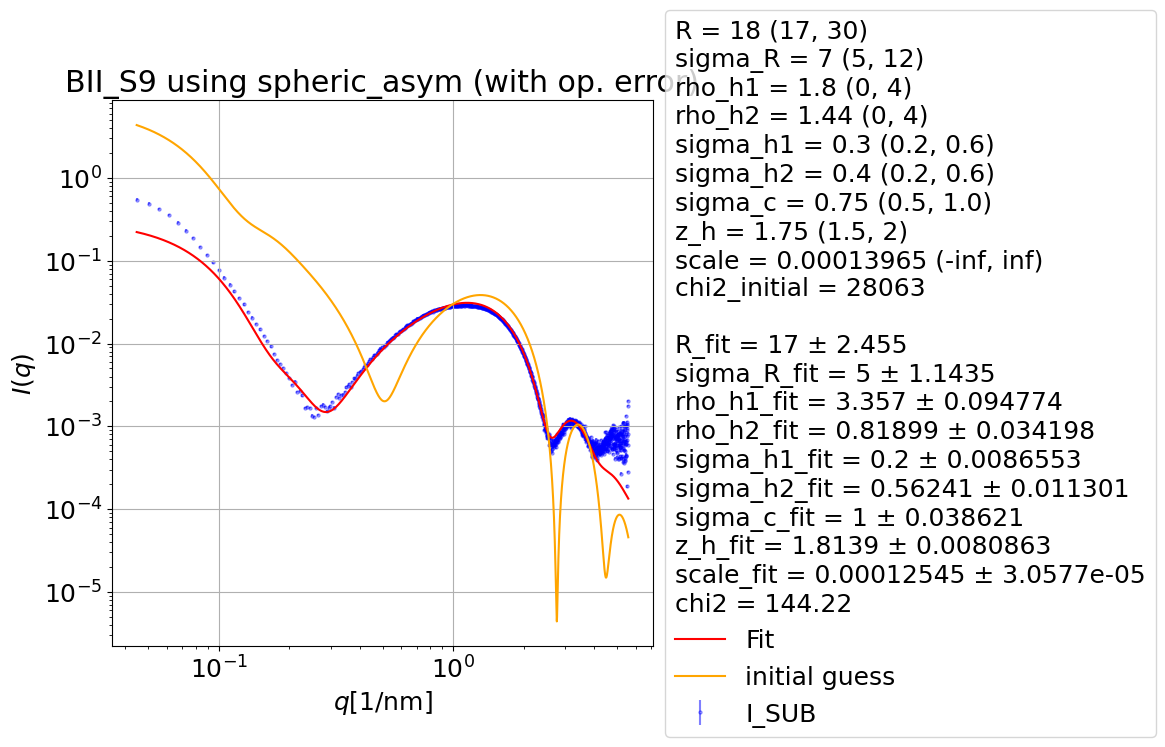

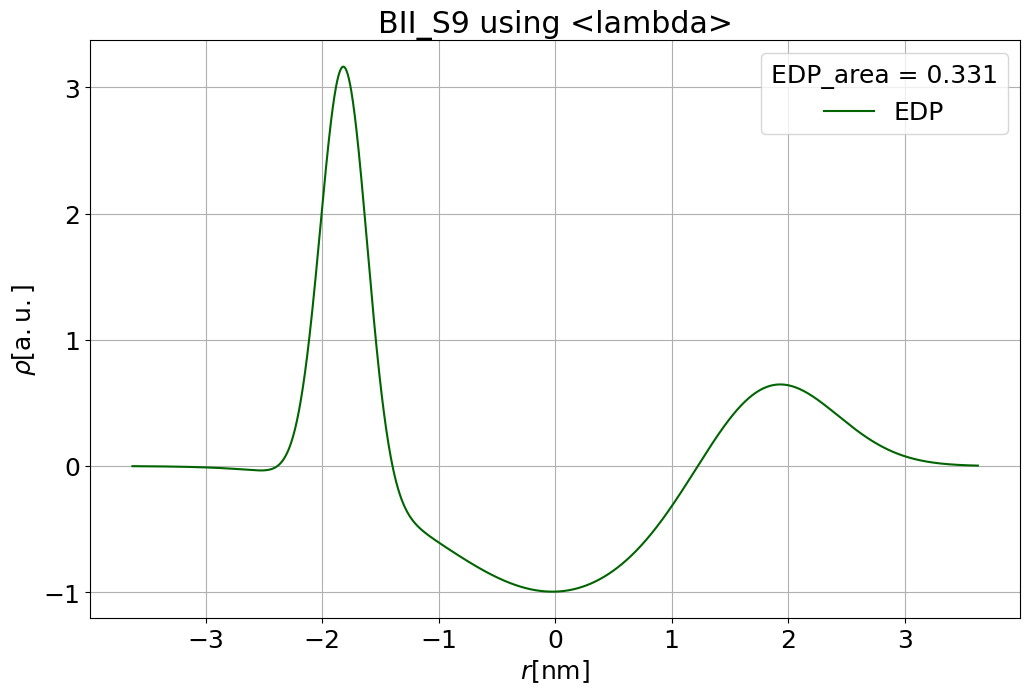

In [49]:
#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = fit.param_names.get(param_set)

perr = np.sqrt(np.diag(pcov))
fit_lib_entry = "["
for name, value in zip(param_names, popt):
    globals()[name] = value
    fit_lib_entry += f"{value:.4g}, "
fit_lib_entry = fit_lib_entry[:-2]
fit_lib_entry += "]"
print(fit_lib_entry)

chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
print(info_text_print)

#=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 10000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,ecolor="Blue", markeredgecolor='Blue', markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{sample} using spheric_asym (with op. error)')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{fit_function.__name__}_op_error2.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()

fig=fit.EDP_plot(R_fit, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text_print, 
             f'{sample} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_op_error2.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

In [8]:
# spheric asym good fits
R_fit = 16.672 ± 0.82179
sigma_R_fit = 3.1798 ± 0.46368
rho_h1_fit = 3.7643 ± 0.13501
rho_h2_fit = 0.72117 ± 0.028021
sigma_h1_fit = 0.1647 ± 0.0084499
sigma_h2_fit = 0.55318 ± 0.012865
sigma_c_fit = 0.88177 ± 0.030086
z_h_fit = 1.8378 ± 0.009789
scale_fit = 0.00013965 ± 1.3577e-05
chi2 = 140.8

SyntaxError: invalid character '±' (U+00B1) (2438376538.py, line 2)

In [ ]:
# ellipsoidal sym
fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h, sigma_h,    sigma_c,      z_h,    scale: fit.ULV_ellipsoid(q, R,  sigma_R,     eps, sigma_eps,  rho_h, sigma_h,    sigma_c,      z_h,    scale,   0, 0, 0)
plt.close("all")

param_set = "ULV_ellipsoid"

q     = q
I     = I 
I_err = Ierr # np.maximum(I, 0) / 30
thinning = 4
q_thinned = q[::thinning]
I_thinned = I[::thinning]
I_err_thinned = I_err[::thinning]

# ========================== Parameters ==========================
R = 20
sigma_R = 5
eps = 1
sigma_eps = 0.2
rho_h = 1.48
sigma_h = 0.3
sigma_c = 0.77
z_h = 1.8
scale = 1e-7
c2 = 0
c3 = 0
c4 = 0.007

# ========================== Setting Bounds ==============================
# popt = [        R_fit,  sigma_R_fit,     eps_fit, sigma_eps_fit,  rho_h_fit, sigma_h_fit,  sigma_c_fit,      z_h_fit,    scale_fit,   c2_fit,   c3_fit,       c4_fit]
p0           = [        R,  sigma_R,     eps, sigma_eps,  rho_h, sigma_h,    sigma_c,      z_h,    scale] # ,   c2,   c3,       c4]
lower_bounds = [        9,        2,     0.8,         0,      0,     0.2,        0.5,      1.5,  -np.inf] # ,    0,    0,  -np.inf]
upper_bounds = [       25,        9,     1.5,       0.7,     10,     0.5,          1,        2,  +np.inf] # ,  0.2,  0.5,  +np.inf]
#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=1000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = fit.param_names.get(param_set)

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = q
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using ellip_sym (op. error)')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)

plt.tight_layout()
# plt.savefig(target_folder / f"LV4_{fit_function.__name__}_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
info_text="_"
#==================== EDP Plot ==================================================
# fig=fit.EDP_plot(R, sigma_h_fit, sigma_h_fit, sigma_c_fit, rho_h_fit, rho_h_fit, z_h_fit, z_h_fit, info_text, 
#              f'{sample} fac={fac} using {fit_function.__name__}')
fig=fit.EDP_plot(R, sigma_h, sigma_h, sigma_c, rho_h, rho_h, z_h, z_h, info_text, 
             f'{BM29.sample_dict[sample]} using ellip_sym (initial guess)')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# pow_law_reality_check(c2_fit, c3_fit, c4_fit)


Computing I(q):  77%|█████████████████▊     | 773/1000 [00:03<00:01, 203.74it/s]Process ForkPoolWorker-4005:
Process ForkPoolWorker-4011:
Process ForkPoolWorker-4015:
Process ForkPoolWorker-4010:
Process ForkPoolWorker-4017:
Process ForkPoolWorker-4020:
Process ForkPoolWorker-4002:
Process ForkPoolWorker-4003:
Process ForkPoolWorker-4007:
Process ForkPoolWorker-4013:
Process ForkPoolWorker-4001:
Process ForkPoolWorker-4016:
Process ForkPoolWorker-4004:
Process ForkPoolWorker-4014:
Process ForkPoolWorker-4012:
Process ForkPoolWorker-4006:
Process ForkPoolWorker-4009:
Process ForkPoolWorker-4008:
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (mo

Computing I(q): 100%|██████████████████████| 1000/1000 [00:05<00:00, 186.13it/s]


2154626.2187963147


Computing I(q): 100%|██████████████████████| 1000/1000 [00:06<00:00, 164.73it/s]


chi2 op. err. /30 33615.26803271342


Computing I(q): 100%|██████████████████████| 1000/1000 [00:05<00:00, 175.27it/s]


chi2 op. err. /20 14940.119125650412


Computing I(q): 100%|██████████████████████| 1000/1000 [00:05<00:00, 185.68it/s]


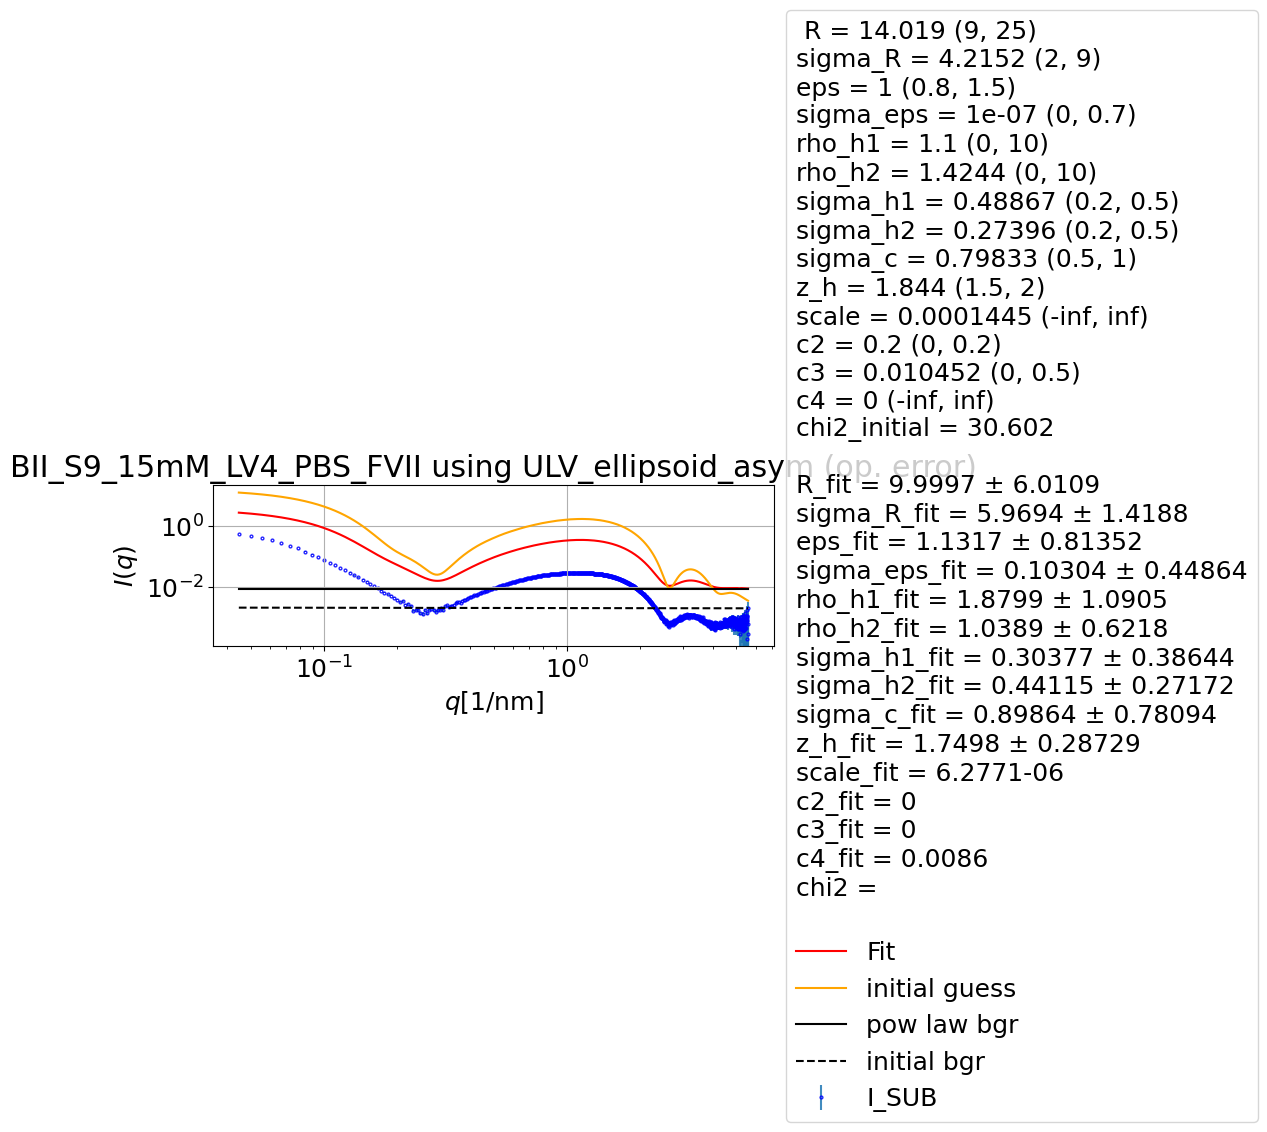

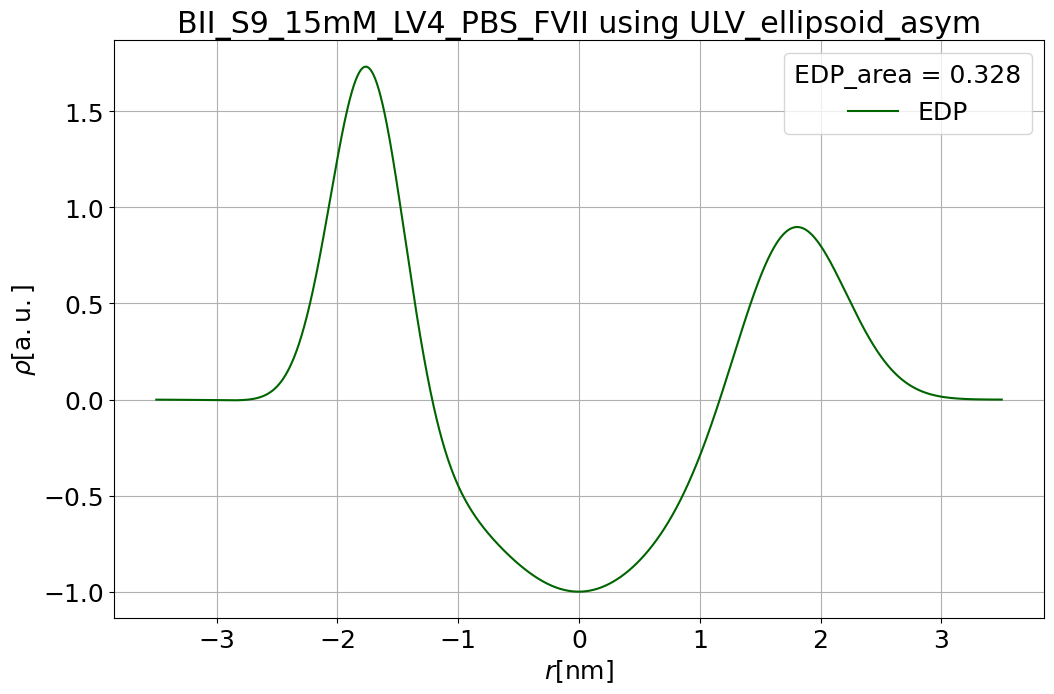

In [ ]:
fit_function = fit.ULV_ellipsoid_asym
plt.close("all")

param_set = "ULV_ellipsoid_asym"

q     = q
I     = I 
I_err = Ierr # np.maximum(I, 0) / 30
I_err_op = np.maximum(I, 0.01) / 30
I_err_op20 = np.maximum(I, 0.01) / 20

thinning = 1
q_thinned = q[::thinning]
I_thinned = I[::thinning]
I_err_thinned = I_err[::thinning]

# ========================== Parameters ==========================
R       = 14.019
sigma_R = 4.2152
eps  = 1
sigma_eps = 0.0000001

rho_h1   = 1.1
rho_h2   = 1.4244
sigma_h1 = 0.48867
sigma_h2 = 0.27396
sigma_c = 0.79833
z_h = 1.844

scale = 0.00002445 
c2    = 0.002
c3    = 0.010452
c4    = 0

# ======================================================================
R_fit = 9.9997 
sigma_R_fit = 5.9694
eps_fit = 1.1317 
sigma_eps_fit = 0.10304 
rho_h1_fit = 1.8799 
rho_h2_fit = 1.0389 
sigma_h1_fit = 0.30377 
sigma_h2_fit = 0.44115 
sigma_c_fit = 0.89864 
z_h_fit = 1.7498 
# scale_fit = 0.0001882 
# c2_fit = 0
# c3_fit = 0 
# c4_fit = 0.079313 + 0.1786
scale_fit = 6.27710549513136e-06
c2_fit = 0
c3_fit = 0
c4_fit = 0.008600995613288826
chi2 = 8.0953

info_text_print = """ R = 14.019 (9, 25)
sigma_R = 4.2152 (2, 9)
eps = 1 (0.8, 1.5)
sigma_eps = 1e-07 (0, 0.7)
rho_h1 = 1.1 (0, 10)
rho_h2 = 1.4244 (0, 10)
sigma_h1 = 0.48867 (0.2, 0.5)
sigma_h2 = 0.27396 (0.2, 0.5)
sigma_c = 0.79833 (0.5, 1)
z_h = 1.844 (1.5, 2)
scale = 0.0001445 (-inf, inf)
c2 = 0.2 (0, 0.2)
c3 = 0.010452 (0, 0.5)
c4 = 0 (-inf, inf)
chi2_initial = 30.602
 
R_fit = 9.9997 ± 6.0109
sigma_R_fit = 5.9694 ± 1.4188
eps_fit = 1.1317 ± 0.81352
sigma_eps_fit = 0.10304 ± 0.44864
rho_h1_fit = 1.8799 ± 1.0905
rho_h2_fit = 1.0389 ± 0.6218
sigma_h1_fit = 0.30377 ± 0.38644
sigma_h2_fit = 0.44115 ± 0.27172
sigma_c_fit = 0.89864 ± 0.78094
z_h_fit = 1.7498 ± 0.28729
scale_fit = 6.2771-06
c2_fit = 0
c3_fit = 0
c4_fit = 0.0086
chi2 = 
"""
# ========================== Setting Bounds ==============================
popt = [        R_fit,  sigma_R_fit,     eps_fit, sigma_eps_fit,  rho_h1_fit, rho_h2_fit,   sigma_h1_fit, sigma_h2_fit,  sigma_c_fit,      z_h_fit,    scale_fit,   c2_fit,   c3_fit,       c4_fit]
p0           = [        R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale,   c2,   c3,       c4]
lower_bounds = [        9,        2,     0.8,         0,       0,      0,        0.2,      0.2,      0.5,      1.5,  -np.inf,    0,    0,  -np.inf]
upper_bounds = [       25,        9,     1.5,       0.7,      10,     10,        0.5,      0.5,        1,        2,  +np.inf,  0.2,  0.5,  +np.inf]
#======================== Fit ===========================================
residuals = I - fit_function(q, *popt)
chi2 = np.sum((residuals / I_err)**2) / (len(I) - len(p0) - 1)
print(chi2)
residuals = I - fit_function(q, *popt)
chi2 = np.sum((residuals / I_err_op)**2) / (len(I) - len(p0) - 1)
print("chi2 op. err. /30", chi2)
residuals = I - fit_function(q, *popt)
chi2 = np.sum((residuals / I_err_op20)**2) / (len(I) - len(p0) - 1)
print("chi2 op. err. /20", chi2)
# popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=1000, p0=p0, bounds = (lower_bounds, upper_bounds))

# param_names = fit.param_names.get(param_set)

# perr = np.sqrt(np.diag(pcov))
# for name, value in zip(param_names, popt):
#     globals()[name] = value
# chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), len(q_thinned))
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='pow law bgr')
plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using {fit_function.__name__} (op. error)')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)

plt.tight_layout()
# plt.savefig(target_folder / f"LV4_{fit_function.__name__}_FINAL_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
info_text="_"
#==================== EDP Plot ==================================================
fig=fit.EDP_plot(R, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text, 
             f'{BM29.sample_dict[sample]} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)